# PRACTICE 2: HANDS-ON PRACTICE WITH PRE-TRAINED NEURAL NETWORK ARCHITECTURES

**Môn học:** Deep Learning - **UTH** - **Giảng viên:** PHd.Nguyễn Thị Khánh Tiên 

**Dataset:** CIFAR-10  

**Pre-trained models:** ResNet-18, VGG-16, DenseNet-121
_________________________________________________________________________________________________
## Mục tiêu
1. Làm quen với việc tải và sử dụng các mô hình pre-trained từ `torchvision.models`.
2. Khám phá kiến trúc, các lớp và tham số của những mô hình đã được huấn luyện trước.
3. Thay thế lớp phân loại cuối để phù hợp với Dataset CIFAR-10 gồm 10 lớp.
4. Thực hiện Transfer Learning và Fine-Tuning để áp dụng mô hình pre-trained vào bài toán phân loại ảnh.
5. Điều chỉnh các siêu tham số như Learning Rate và Batch Size.
6. Chuẩn bị dữ liệu, xây dựng quy trình huấn luyện và sử dụng TensorBoard để theo dõi quá trình Training.
7. Đánh giá hiệu suất trên tập Test và so sánh kết quả giữa các mô hình.


## 1. Import Libraries và Configure Device

In [2]:
import os
import os

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
import time
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torch.utils.tensorboard import SummaryWriter

from torchvision import datasets, transforms, models
import torchvision.utils as vutils

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch version:", torch.__version__)
print("Torchvision version:", __import__("torchvision").__version__)
print("Training device:", device)

PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu
Training device: cpu


## 2. Prepare CIFAR-10 Dataset

CIFAR-10 gồm 60.000 ảnh màu thuộc 10 lớp: 50.000 ảnh Train và 10.000 ảnh Test. Tập Train tiếp tục được chia thành Train và Validation. Tập Test được giữ riêng để đánh giá cuối cùng.

- `Resize((64, 64))`: thay đổi kích thước ảnh để phù hợp hơn với tài nguyên CPU.
- `RandomHorizontalFlip()`: tăng cường dữ liệu cho tập Train.
- `Normalize(...)`: chuẩn hóa theo thống kê ImageNet vì mô hình được pre-train trên ImageNet.
- `DataLoader`: chia dữ liệu thành các batch.

In [10]:
BATCH_SIZE = 32
IMAGE_SIZE = 64

# Chế độ chạy thử để kiểm tra notebook trên CPU.
# Có thể tăng các giá trị này khi muốn thực nghiệm trên toàn bộ dữ liệu.
QUICK_RUN = True
TRAIN_LIMIT = 2000 if QUICK_RUN else None
VAL_LIMIT = 500 if QUICK_RUN else None
TEST_LIMIT = 500 if QUICK_RUN else None

mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_dataset_aug = datasets.CIFAR10(
    root="./data", train=True, download=True, transform=train_transform
)
train_dataset_eval = datasets.CIFAR10(
    root="./data", train=True, download=True, transform=eval_transform
)
test_dataset = datasets.CIFAR10(
    root="./data", train=False, download=True, transform=eval_transform
)

# Chia Train thành Train và Validation bằng cùng một danh sách chỉ số.
generator = torch.Generator().manual_seed(SEED)
indices = torch.randperm(len(train_dataset_aug), generator=generator).tolist()
train_indices = indices[5000:]
val_indices = indices[:5000]

if QUICK_RUN:
    train_indices = train_indices[:TRAIN_LIMIT]
    val_indices = val_indices[:VAL_LIMIT]
    test_indices = list(range(TEST_LIMIT))
else:
    test_indices = list(range(len(test_dataset)))

train_subset = Subset(train_dataset_aug, train_indices)
val_subset = Subset(train_dataset_eval, val_indices)
test_subset = Subset(test_dataset, test_indices)

def create_loaders(batch_size=BATCH_SIZE):
    train_loader = DataLoader(
        train_subset, batch_size=batch_size, shuffle=True, num_workers=0
    )
    val_loader = DataLoader(
        val_subset, batch_size=batch_size, shuffle=False, num_workers=0
    )
    test_loader = DataLoader(
        test_subset, batch_size=batch_size, shuffle=False, num_workers=0
    )
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = create_loaders()

classes = train_dataset_aug.classes
print("Classes:", classes)
print("Train samples:", len(train_subset))
print("Validation samples:", len(val_subset))
print("Test samples:", len(test_subset))
print("Batch size:", BATCH_SIZE)

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train samples: 2000
Validation samples: 500
Test samples: 500
Batch size: 32


### 2.1. Visualize Sample Images

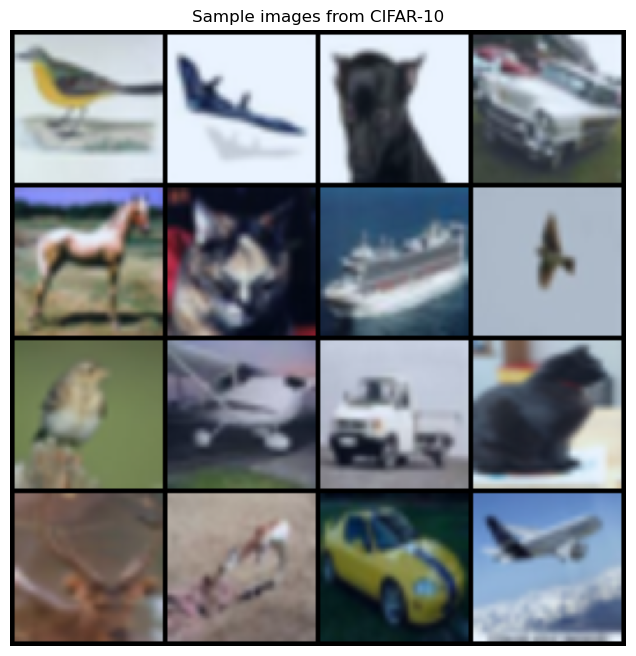

Image batch shape: torch.Size([32, 3, 64, 64])
Label batch shape: torch.Size([32])


In [13]:
images, labels = next(iter(train_loader))
grid = vutils.make_grid(images[:16], nrow=4, normalize=True)
plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.title("Sample images from CIFAR-10")
plt.show()

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

## 3. Load and Explore Pre-trained Model Architectures

Các mô hình sử dụng trọng số đã được huấn luyện trên ImageNet. `weights=...DEFAULT` là API hiện hành thay cho cách viết cũ `pretrained=True` trong nhiều phiên bản torchvision.

In [14]:
weights_resnet = models.ResNet18_Weights.DEFAULT
weights_vgg = models.VGG16_Weights.DEFAULT
weights_densenet = models.DenseNet121_Weights.DEFAULT

resnet = models.resnet18(weights=weights_resnet)
vgg = models.vgg16(weights=weights_vgg)
densenet = models.densenet121(weights=weights_densenet)

print("RESNET-18")
print(resnet)
print("\nVGG-16")
print(vgg)
print("\nDENSENET-121")
print(densenet)

RESNET-18
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_r

In [16]:
print("ResNet18 final layer:", resnet.fc)
print("VGG16 final layer:", vgg.classifier[6])
print("DenseNet121 final layer:", densenet.classifier)

def count_parameters(model):
    total = sum(parameter.numel() for parameter in model.parameters())
    trainable = sum(
        parameter.numel() for parameter in model.parameters()
        if parameter.requires_grad
    )
    return total, trainable

for name, model in [
    ("ResNet18", resnet),
    ("VGG16", vgg),
    ("DenseNet121", densenet)
]:
    total, trainable = count_parameters(model)
    print(f"{name}: total={total:,}, trainable={trainable:,}")

ResNet18 final layer: Linear(in_features=512, out_features=1000, bias=True)
VGG16 final layer: Linear(in_features=4096, out_features=1000, bias=True)
DenseNet121 final layer: Linear(in_features=1024, out_features=1000, bias=True)
ResNet18: total=11,689,512, trainable=11,689,512
VGG16: total=138,357,544, trainable=138,357,544
DenseNet121: total=7,978,856, trainable=7,978,856


## 4. Adapt Models: Transfer Learning và Fine-Tuning

- **Transfer Learning:** đóng băng các tầng trích xuất đặc trưng, chỉ huấn luyện tầng phân loại cuối.
- **Fine-Tuning:** mở thêm một phần các tầng cuối để cập nhật trọng số trên CIFAR-10.

Mỗi mô hình có vị trí classifier khác nhau nên cần thay đúng tầng cuối.

In [17]:
def build_model(model_name, num_classes=10, mode="transfer_learning"):
    if model_name == "resnet18":
        model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        for parameter in model.parameters():
            parameter.requires_grad = False
        if mode == "fine_tuning":
            for parameter in model.layer4.parameters():
                parameter.requires_grad = True
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif model_name == "vgg16":
        model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
        for parameter in model.parameters():
            parameter.requires_grad = False
        if mode == "fine_tuning":
            for parameter in model.features[24:].parameters():
                parameter.requires_grad = True
        model.classifier[6] = nn.Linear(
            model.classifier[6].in_features, num_classes
        )

    elif model_name == "densenet121":
        model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
        for parameter in model.parameters():
            parameter.requires_grad = False
        if mode == "fine_tuning":
            for parameter in model.features.denseblock4.parameters():
                parameter.requires_grad = True
            for parameter in model.features.norm5.parameters():
                parameter.requires_grad = True
        model.classifier = nn.Linear(
            model.classifier.in_features, num_classes
        )

    else:
        raise ValueError("Model name must be resnet18, vgg16, or densenet121.")

    return model.to(device)

for name in ["resnet18", "vgg16", "densenet121"]:
    model = build_model(name, mode="transfer_learning")
    total, trainable = count_parameters(model)
    print(
        f"{name}: total={total:,}, trainable={trainable:,} "
        f"({100 * trainable / total:.2f}%)"
    )
    del model

resnet18: total=11,181,642, trainable=5,130 (0.05%)
vgg16: total=134,301,514, trainable=40,970 (0.03%)
densenet121: total=6,964,106, trainable=10,250 (0.15%)


## 5. Training Function và TensorBoard

Hàm huấn luyện bên dưới ghi nhận Training Loss, Validation Loss, Training Accuracy và Validation Accuracy lên TensorBoard. Mô hình tốt nhất theo Validation Loss sẽ được lưu lại.

**Lưu ý:** Validation được dùng để theo dõi/chọn mô hình; Test chỉ được dùng ở bước đánh giá cuối.

In [19]:
def train_model(
    model,
    model_name,
    mode,
    train_loader,
    val_loader,
    learning_rate=0.001,
    epochs=1,
    optimizer_name="Adam",
    run_name=None
):
    criterion = nn.CrossEntropyLoss()
    trainable_parameters = [
        parameter for parameter in model.parameters()
        if parameter.requires_grad
    ]

    if optimizer_name == "Adam":
        optimizer = optim.Adam(trainable_parameters, lr=learning_rate)
    elif optimizer_name == "SGD":
        optimizer = optim.SGD(
            trainable_parameters, lr=learning_rate, momentum=0.9
        )
    else:
        raise ValueError("optimizer_name must be Adam or SGD.")

    if run_name is None:
        run_name = f"{model_name}_{mode}_{optimizer_name}_lr{learning_rate}"

    writer = SummaryWriter(log_dir=os.path.join("runs", run_name))
    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    history = []

    sample_images, _ = next(iter(train_loader))
    writer.add_image(
        "Sample_Images",
        vutils.make_grid(sample_images[:16], normalize=True),
        0
    )

    try:
        writer.add_graph(model, sample_images[:1].to(device))
    except Exception as error:
        print("Không thể ghi Model Graph:", error)

    for epoch in range(1, epochs + 1):
        start_time = time.time()
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, targets in train_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            predictions = outputs.argmax(dim=1)
            total += targets.size(0)
            correct += (predictions == targets).sum().item()

        train_loss = running_loss / total
        train_accuracy = 100.0 * correct / total

        model.eval()
        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs = inputs.to(device)
                targets = targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)

                val_loss_sum += loss.item() * inputs.size(0)
                predictions = outputs.argmax(dim=1)
                val_total += targets.size(0)
                val_correct += (predictions == targets).sum().item()

        val_loss = val_loss_sum / val_total
        val_accuracy = 100.0 * val_correct / val_total

        writer.add_scalar("Loss/Train", train_loss, epoch)
        writer.add_scalar("Loss/Validation", val_loss, epoch)
        writer.add_scalar("Accuracy/Train", train_accuracy, epoch)
        writer.add_scalar("Accuracy/Validation", val_accuracy, epoch)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy
        })

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())

        elapsed = time.time() - start_time
        print(
            f"Epoch {epoch}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.2f}% | "
            f"Time: {elapsed:.1f}s"
        )

    writer.close()
    model.load_state_dict(best_state)

    os.makedirs("checkpoints", exist_ok=True)
    checkpoint_path = os.path.join("checkpoints", f"{run_name}_best.pth")
    torch.save(model.state_dict(), checkpoint_path)

    return model, history, checkpoint_path

## 6. Experiment 1: Compare Different Pre-trained Models

Thực nghiệm ResNet18, VGG16 và DenseNet121 trên cùng dataset, cùng chế độ Transfer Learning và cùng cấu hình huấn luyện để có thể so sánh công bằng.

Sử dụng 5 epochs cho mỗi mô hình để theo dõi quá trình huấn luyện và so sánh kết quả trên cùng tập dữ liệu.

In [27]:
EPOCHS_COMPARE =  5
COMPARE_LR = 0.001
COMPARE_BATCH_SIZE = 32

compare_train_loader, compare_val_loader, compare_test_loader = create_loaders(
    COMPARE_BATCH_SIZE
)

model_results = []
trained_model_paths = {}

for model_name in ["resnet18", "vgg16", "densenet121"]:
    print("\n" + "=" * 60)
    print("Training:", model_name)

    model = build_model(
        model_name, num_classes=10, mode="transfer_learning"
    )

    model, history, checkpoint_path = train_model(
        model=model,
        model_name=model_name,
        mode="transfer_learning",
        train_loader=compare_train_loader,
        val_loader=compare_val_loader,
        learning_rate=COMPARE_LR,
        epochs=EPOCHS_COMPARE,
        optimizer_name="Adam"
    )

    final_record = history[-1]
    model_results.append({
        "model": model_name,
        "mode": "transfer_learning",
        "learning_rate": COMPARE_LR,
        "batch_size": COMPARE_BATCH_SIZE,
        "optimizer": "Adam",
        "train_accuracy": final_record["train_accuracy"],
        "validation_accuracy": final_record["val_accuracy"],
        "validation_loss": final_record["val_loss"],
        "checkpoint": checkpoint_path
    })

    trained_model_paths[model_name] = checkpoint_path
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

model_comparison_df = pd.DataFrame(model_results)
model_comparison_df


Training: resnet18


c:\Users\PC\anaconda3\Lib\site-packages\torch\jit\_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\Users\PC\anaconda3\Lib\site-packages\torch\jit\_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Epoch 1/5 | Train Loss: 1.9782 | Train Acc: 31.00% | Val Loss: 1.5507 | Val Acc: 48.80% | Time: 30.7s
Epoch 2/5 | Train Loss: 1.4224 | Train Acc: 52.20% | Val Loss: 1.3645 | Val Acc: 53.60% | Time: 24.1s
Epoch 3/5 | Train Loss: 1.2394 | Train Acc: 60.15% | Val Loss: 1.2849 | Val Acc: 55.60% | Time: 36.3s
Epoch 4/5 | Train Loss: 1.1211 | Train Acc: 63.05% | Val Loss: 1.2372 | Val Acc: 57.60% | Time: 36.7s
Epoch 5/5 | Train Loss: 1.0946 | Train Acc: 62.85% | Val Loss: 1.2557 | Val Acc: 56.00% | Time: 28.3s

Training: vgg16
Epoch 1/5 | Train Loss: 1.3053 | Train Acc: 55.30% | Val Loss: 0.9269 | Val Acc: 69.60% | Time: 115.1s
Epoch 2/5 | Train Loss: 0.8531 | Train Acc: 72.15% | Val Loss: 0.9181 | Val Acc: 68.80% | Time: 109.2s
Epoch 3/5 | Train Loss: 0.7605 | Train Acc: 72.80% | Val Loss: 0.9050 | Val Acc: 68.20% | Time: 116.3s
Epoch 4/5 | Train Loss: 0.6675 | Train Acc: 77.75% | Val Loss: 0.9538 | Val Acc: 67.80% | Time: 122.8s
Epoch 5/5 | Train Loss: 0.6001 | Train Acc: 78.15% | Val Loss

,model,mode,learning_rate,batch_size,optimizer,train_accuracy,validation_accuracy,validation_loss,checkpoint
0,resnet18,transfer_learning,0.001,32,Adam,62.85,56.0,1.255749,checkpoints\resnet18_transfer_learning_Adam_lr...
1,vgg16,transfer_learning,0.001,32,Adam,78.15,68.0,0.972134,checkpoints\vgg16_transfer_learning_Adam_lr0.0...
2,densenet121,transfer_learning,0.001,32,Adam,70.40,62.8,1.106380,checkpoints\densenet121_transfer_learning_Adam...


### 6.1. Thực nghiệm Fine-Tuning

Ngoài Transfer Learning, thực hiện thêm Fine-Tuning trên ResNet18: mở khóa `layer4` và huấn luyện cùng tầng phân loại cuối. Learning rate nhỏ hơn thường được dùng khi cập nhật các trọng số pre-trained.

In [28]:
fine_tune_model = build_model(
    "resnet18", num_classes=10, mode="fine_tuning"
)

fine_tune_model, fine_tune_history, fine_tune_checkpoint = train_model(
    model=fine_tune_model,
    model_name="resnet18",
    mode="fine_tuning",
    train_loader=compare_train_loader,
    val_loader=compare_val_loader,
    learning_rate=0.0001,
    epochs=EPOCHS_COMPARE,
    optimizer_name="Adam",
    run_name="resnet18_fine_tuning_adam_lr0.0001"
)

fine_tune_record = fine_tune_history[-1]
fine_tune_result = pd.DataFrame([{
    "model": "resnet18",
    "mode": "fine_tuning",
    "learning_rate": 0.0001,
    "batch_size": COMPARE_BATCH_SIZE,
    "optimizer": "Adam",
    "train_accuracy": fine_tune_record["train_accuracy"],
    "validation_accuracy": fine_tune_record["val_accuracy"],
    "validation_loss": fine_tune_record["val_loss"],
    "checkpoint": fine_tune_checkpoint
}])

fine_tune_result

c:\Users\PC\anaconda3\Lib\site-packages\torch\jit\_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\Users\PC\anaconda3\Lib\site-packages\torch\jit\_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Epoch 1/5 | Train Loss: 1.5592 | Train Acc: 47.05% | Val Loss: 1.0592 | Val Acc: 64.80% | Time: 38.6s
Epoch 2/5 | Train Loss: 0.7066 | Train Acc: 78.45% | Val Loss: 0.8977 | Val Acc: 69.40% | Time: 36.2s
Epoch 3/5 | Train Loss: 0.4402 | Train Acc: 88.05% | Val Loss: 0.8580 | Val Acc: 70.40% | Time: 37.6s
Epoch 4/5 | Train Loss: 0.2610 | Train Acc: 94.20% | Val Loss: 0.8184 | Val Acc: 73.60% | Time: 36.7s
Epoch 5/5 | Train Loss: 0.1882 | Train Acc: 96.00% | Val Loss: 0.8119 | Val Acc: 74.80% | Time: 44.2s


,model,mode,learning_rate,batch_size,optimizer,train_accuracy,validation_accuracy,validation_loss,checkpoint
0,resnet18,fine_tuning,0.0001,32,Adam,96.0,74.8,0.811918,checkpoints\resnet18_fine_tuning_adam_lr0.0001...


## 7. Experiment 2: Adjust Hyperparameters

Thay đổi Learning Rate và Batch Size trên cùng một kiến trúc ResNet18 để quan sát sự khác biệt giữa các cấu hình siêu tham số.

Các cấu hình thực nghiệm:
- Cấu hình 1: Learning Rate = 0.001, Batch Size = 32.
- Cấu hình 2: Learning Rate = 0.0001, Batch Size = 64.

**Lưu ý:** Hai cấu hình thay đổi đồng thời Learning Rate và Batch Size, do đó kết quả phản ánh sự khác biệt giữa hai cấu hình, chưa xác định được ảnh hưởng riêng của từng siêu tham số.

Có thể bổ sung SGD hoặc các giá trị khác nếu tài nguyên máy cho phép.

In [29]:
HYPERPARAMETER_CONFIGS = [
    {"learning_rate": 0.001, "batch_size": 32, "optimizer": "Adam"},
    {"learning_rate": 0.0001, "batch_size": 64, "optimizer": "Adam"}
]

EPOCHS_HYPERPARAMETER = 5
hyperparameter_results = []

for config_index, config in enumerate(HYPERPARAMETER_CONFIGS, start=1):
    print("\n" + "=" * 60)
    print("Hyperparameter configuration:", config)

    hp_train_loader, hp_val_loader, _ = create_loaders(config["batch_size"])
    model = build_model(
        "resnet18", num_classes=10, mode="transfer_learning"
    )

    run_name = (
        f"resnet18_lr{config['learning_rate']}_"
        f"bs{config['batch_size']}_{config['optimizer']}"
    )

    model, history, checkpoint_path = train_model(
        model=model,
        model_name="resnet18",
        mode="transfer_learning",
        train_loader=hp_train_loader,
        val_loader=hp_val_loader,
        learning_rate=config["learning_rate"],
        epochs=EPOCHS_HYPERPARAMETER,
        optimizer_name=config["optimizer"],
        run_name=run_name
    )

    final_record = history[-1]
    hyperparameter_results.append({
        "learning_rate": config["learning_rate"],
        "batch_size": config["batch_size"],
        "optimizer": config["optimizer"],
        "train_accuracy": final_record["train_accuracy"],
        "validation_accuracy": final_record["val_accuracy"],
        "validation_loss": final_record["val_loss"],
        "checkpoint": checkpoint_path
    })

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

hyperparameter_df = pd.DataFrame(hyperparameter_results)
hyperparameter_df


Hyperparameter configuration: {'learning_rate': 0.001, 'batch_size': 32, 'optimizer': 'Adam'}


c:\Users\PC\anaconda3\Lib\site-packages\torch\jit\_trace.py:1006: FutureWarning: `torch.jit.trace` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
c:\Users\PC\anaconda3\Lib\site-packages\torch\jit\_trace.py:1145: FutureWarning: `torch.jit.trace_method` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Epoch 1/5 | Train Loss: 1.9884 | Train Acc: 31.20% | Val Loss: 1.5909 | Val Acc: 47.60% | Time: 20.5s
Epoch 2/5 | Train Loss: 1.4082 | Train Acc: 52.80% | Val Loss: 1.3845 | Val Acc: 54.40% | Time: 19.2s
Epoch 3/5 | Train Loss: 1.2526 | Train Acc: 57.60% | Val Loss: 1.2729 | Val Acc: 58.60% | Time: 19.5s
Epoch 4/5 | Train Loss: 1.1232 | Train Acc: 63.65% | Val Loss: 1.2865 | Val Acc: 57.40% | Time: 19.5s
Epoch 5/5 | Train Loss: 1.0964 | Train Acc: 63.50% | Val Loss: 1.2792 | Val Acc: 58.40% | Time: 19.3s

Hyperparameter configuration: {'learning_rate': 0.0001, 'batch_size': 64, 'optimizer': 'Adam'}
Epoch 1/5 | Train Loss: 2.6085 | Train Acc: 8.25% | Val Loss: 2.4593 | Val Acc: 10.60% | Time: 18.6s
Epoch 2/5 | Train Loss: 2.4450 | Train Acc: 13.10% | Val Loss: 2.3165 | Val Acc: 16.00% | Time: 18.5s
Epoch 3/5 | Train Loss: 2.3389 | Train Acc: 13.40% | Val Loss: 2.2023 | Val Acc: 21.80% | Time: 18.5s
Epoch 4/5 | Train Loss: 2.2184 | Train Acc: 19.90% | Val Loss: 2.1071 | Val Acc: 24.40% |

,learning_rate,batch_size,optimizer,train_accuracy,validation_accuracy,validation_loss,checkpoint
0,0.0010,32,Adam,63.5,58.4,1.279236,checkpoints\resnet18_lr0.001_bs32_Adam_best.pth
1,0.0001,64,Adam,23.5,31.0,2.019271,checkpoints\resnet18_lr0.0001_bs64_Adam_best.pth


## 8. Final Evaluation on Test Dataset

Đánh giá các mô hình đã huấn luyện trên tập Test độc lập. Kết quả Test không được dùng để điều chỉnh hyperparameters.

In [30]:
def evaluate_model(model, data_loader):
    criterion = nn.CrossEntropyLoss()
    model.eval()

    loss_sum = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, targets in data_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            loss_sum += loss.item() * inputs.size(0)
            predictions = outputs.argmax(dim=1)
            total += targets.size(0)
            correct += (predictions == targets).sum().item()

    return loss_sum / total, 100.0 * correct / total

test_results = []

evaluation_checkpoints = dict(trained_model_paths)
evaluation_checkpoints["resnet18_fine_tuning"] = fine_tune_checkpoint

for model_name, checkpoint_path in evaluation_checkpoints.items():
    architecture_name = "resnet18" if model_name == "resnet18_fine_tuning" else model_name
    mode_name = "fine_tuning" if model_name == "resnet18_fine_tuning" else "transfer_learning"
    model = build_model(
        architecture_name, num_classes=10, mode=mode_name
    )
    model.load_state_dict(torch.load(
        checkpoint_path, map_location=device, weights_only=True
    ))

    test_loss, test_accuracy = evaluate_model(model, test_loader)
    test_results.append({
        "model": architecture_name,
        "mode": mode_name,
        "test_loss": test_loss,
        "test_accuracy": test_accuracy
    })

    print(
        f"{model_name} ({mode_name}): Test Loss = {test_loss:.4f}, "
        f"Test Accuracy = {test_accuracy:.2f}%"
    )
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

test_comparison_df = pd.DataFrame(test_results)
test_comparison_df

resnet18 (transfer_learning): Test Loss = 1.2860, Test Accuracy = 55.80%
vgg16 (transfer_learning): Test Loss = 1.0279, Test Accuracy = 66.20%
densenet121 (transfer_learning): Test Loss = 1.2760, Test Accuracy = 57.00%
resnet18_fine_tuning (fine_tuning): Test Loss = 0.8796, Test Accuracy = 71.60%


,model,mode,test_loss,test_accuracy
0,resnet18,transfer_learning,1.286024,55.8
1,vgg16,transfer_learning,1.027897,66.2
2,densenet121,transfer_learning,1.275976,57.0
3,resnet18,fine_tuning,0.879642,71.6


## 9. Visualize Results, TensorBoard và Save Results

Bảng kết quả giúp so sánh các kiến trúc và cấu hình hyperparameters. TensorBoard hiển thị đường Loss/Accuracy theo epoch, ảnh mẫu và Model Graph (nếu môi trường hỗ trợ).

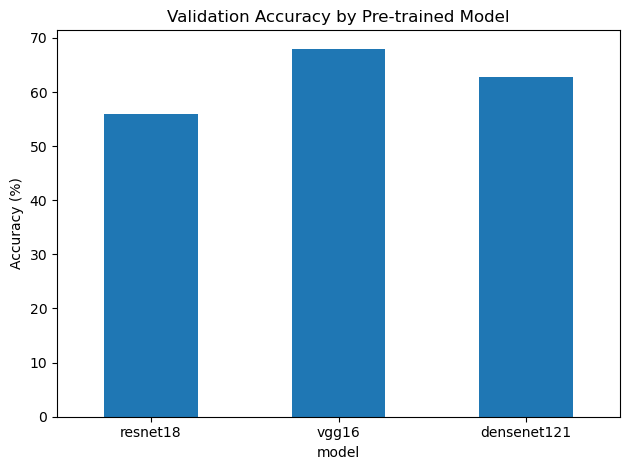

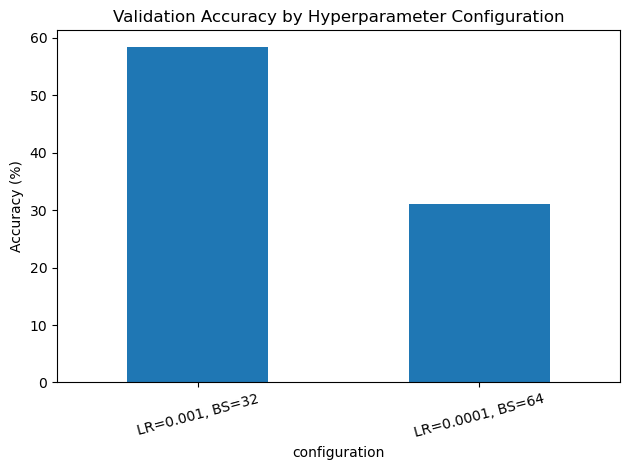

Đã lưu các bảng kết quả trong thư mục results.


In [31]:
if not model_comparison_df.empty:
    model_comparison_df.plot(
        x="model",
        y="validation_accuracy",
        kind="bar",
        legend=False,
        title="Validation Accuracy by Pre-trained Model",
        ylabel="Accuracy (%)"
    )
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

if not hyperparameter_df.empty:
    hyperparameter_df["configuration"] = hyperparameter_df.apply(
        lambda row: f"LR={row['learning_rate']}, BS={row['batch_size']}",
        axis=1
    )
    hyperparameter_df.plot(
        x="configuration",
        y="validation_accuracy",
        kind="bar",
        legend=False,
        title="Validation Accuracy by Hyperparameter Configuration",
        ylabel="Accuracy (%)"
    )
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

os.makedirs("results", exist_ok=True)
model_comparison_df.to_csv(
    "results/model_comparison.csv", index=False
)
hyperparameter_df.to_csv(
    "results/hyperparameter_comparison.csv", index=False
)
test_comparison_df.to_csv(
    "results/test_comparison.csv", index=False
)

print("Đã lưu các bảng kết quả trong thư mục results.")

In [1]:
# Mở TensorBoard trong Jupyter Notebook
%load_ext tensorboard
%tensorboard --logdir runs

Launching TensorBoard...

## 10. Conclusion

Sau khi hoàn thành quá trình thực nghiệm, có thể đưa ra các nhận xét sau:

1. So sánh Validation Accuracy và Test Accuracy giữa ResNet18, VGG16 và DenseNet121.
2. Nhận xét ảnh hưởng của các cấu hình Learning Rate và Batch Size.
3. Quan sát Loss và Accuracy trên TensorBoard để đánh giá quá trình huấn luyện.
4. So sánh hiệu quả giữa Transfer Learning và Fine-Tuning trên mô hình ResNet18.
5. Nêu các hạn chế của thực nghiệm như thời gian huấn luyện, thiết bị CPU/GPU, số lượng ảnh và số Epoch.

Các nhận xét định lượng cần dựa trên kết quả thực nghiệm thực tế.

In [38]:

def generate_conclusion_vietnamese():
    conclusions = []

    def add(text=""):
        conclusions.append(text)
        print(text)

    add("=" * 70)
    add("10. KẾT LUẬN")
    add("=" * 70)

    add("\n1. SO SÁNH CÁC MÔ HÌNH PRE-TRAINED")

    transfer_results = test_comparison_df[
        test_comparison_df["mode"] == "transfer_learning"
    ]

    comparison = model_comparison_df.merge(
        transfer_results,
        on=["model", "mode"],
        how="left"
    )

    model_names = {
        "resnet18": "ResNet18",
        "vgg16": "VGG16",
        "densenet121": "DenseNet121"
    }

    for _, row in comparison.iterrows():
        name = model_names.get(row["model"], row["model"])
        add(
            f"- {name}: Độ chính xác Validation đạt "
            f"{row['validation_accuracy']:.2f}%, "
            f"độ chính xác Test đạt {row['test_accuracy']:.2f}%."
        )

    if not comparison.empty:
        best = comparison.loc[comparison["test_accuracy"].idxmax()]
        add(
            f"=> {model_names.get(best['model'], best['model'])} "
            f"là mô hình có kết quả tốt nhất trong nhóm Transfer Learning, "
            f"với độ chính xác Test đạt {best['test_accuracy']:.2f}%."
        )

    add("\n2. PHÂN TÍCH SIÊU THAM SỐ")

    for _, row in hyperparameter_df.iterrows():
        add(
            f"- Learning Rate = {row['learning_rate']}, "
            f"Batch Size = {row['batch_size']}, "
            f"Optimizer = {row['optimizer']}: "
            f"Validation Accuracy đạt "
            f"{row['validation_accuracy']:.2f}%."
        )

    if not hyperparameter_df.empty:
        best_config = hyperparameter_df.loc[
            hyperparameter_df["validation_accuracy"].idxmax()
        ]
        add(
            f"=> Cấu hình tốt nhất trong thí nghiệm là "
            f"Learning Rate = {best_config['learning_rate']}, "
            f"Batch Size = {best_config['batch_size']}, "
            f"Optimizer = {best_config['optimizer']}."
        )

    add(
        "Lưu ý: Learning Rate và Batch Size được thay đổi đồng thời, "
        "do đó chưa thể xác định ảnh hưởng riêng của từng thông số."
    )

    add("\n3. ĐÁNH GIÁ QUÁ TRÌNH HUẤN LUYỆN BẰNG TENSORBOARD")

    try:
        from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

        for root, _, files in os.walk("runs"):
            if any(f.startswith("events.out.tfevents") for f in files):
                accumulator = EventAccumulator(root)
                accumulator.Reload()
                tags = accumulator.Tags().get("scalars", [])

                if not tags:
                    continue

                add(f"- Thí nghiệm: {os.path.basename(root)}")

                for tag in [
                    "Loss/Train",
                    "Loss/Validation",
                    "Accuracy/Train",
                    "Accuracy/Validation"
                ]:
                    if tag in tags:
                        values = accumulator.Scalars(tag)
                        if values:
                            first = values[0].value
                            last = values[-1].value
                            add(
                                f"  + {tag}: "
                                f"Giá trị đầu = {first:.4f}, "
                                f"giá trị cuối = {last:.4f}."
                            )

        add(
            "TensorBoard hỗ trợ theo dõi Loss và Accuracy trên tập Train "
            "và Validation qua từng epoch, từ đó quan sát quá trình hội tụ "
            "và dấu hiệu overfitting."
        )

    except Exception as error:
        add(f"- Không thể đọc dữ liệu TensorBoard: {error}")

    add("\n4. SO SÁNH TRANSFER LEARNING VÀ FINE-TUNING")

    transfer = test_comparison_df[
        (test_comparison_df["model"] == "resnet18") &
        (test_comparison_df["mode"] == "transfer_learning")
    ]

    fine_tune = test_comparison_df[
        (test_comparison_df["model"] == "resnet18") &
        (test_comparison_df["mode"] == "fine_tuning")
    ]

    if not transfer.empty and not fine_tune.empty:
        transfer_acc = transfer.iloc[0]["test_accuracy"]
        fine_tune_acc = fine_tune.iloc[0]["test_accuracy"]
        difference = fine_tune_acc - transfer_acc

        add(f"- Transfer Learning: {transfer_acc:.2f}%.")
        add(f"- Fine-Tuning: {fine_tune_acc:.2f}%.")

        if difference > 0:
            add(
                f"=> Fine-Tuning giúp tăng độ chính xác thêm "
                f"{difference:.2f} điểm phần trăm so với Transfer Learning."
            )
        elif difference < 0:
            add(
                f"=> Fine-Tuning làm giảm độ chính xác "
                f"{abs(difference):.2f} điểm phần trăm."
            )
        else:
            add("=> Hai phương pháp đạt độ chính xác bằng nhau.")

    add("\n5. HẠN CHẾ CỦA THỰC NGHIỆM")
    add(f"- Thiết bị huấn luyện: {device}.")
    add(f"- Chế độ Quick Run: {QUICK_RUN}.")
    add(f"- Kích thước ảnh: {IMAGE_SIZE} x {IMAGE_SIZE}.")
    add(f"- Số epoch so sánh mô hình: {EPOCHS_COMPARE}.")
    add(f"- Số epoch thử nghiệm siêu tham số: {EPOCHS_HYPERPARAMETER}.")
    add(f"- Số ảnh Train: {len(train_subset)}.")
    add(f"- Số ảnh Validation: {len(val_subset)}.")
    add(f"- Số ảnh Test: {len(test_subset)}.")
    add(
        "Do giới hạn tài nguyên phần cứng và số lượng dữ liệu sử dụng, "
        "kết quả thực nghiệm có thể chưa phản ánh đầy đủ khả năng "
        "tổng quát hóa của các mô hình."
    )

    add("\n" + "=" * 70)
    add("HOÀN THÀNH TẠO KẾT LUẬN")
    add("=" * 70)

    os.makedirs("results", exist_ok=True)

    with open("results/ket_luan.txt", "w", encoding="utf-8") as file:
        file.write("\n".join(conclusions))

    print("\nĐã lưu kết luận : results/ket_luan.txt")


generate_conclusion_vietnamese()


10. KẾT LUẬN

1. SO SÁNH CÁC MÔ HÌNH PRE-TRAINED
- ResNet18: Độ chính xác Validation đạt 56.00%, độ chính xác Test đạt 55.80%.
- VGG16: Độ chính xác Validation đạt 68.00%, độ chính xác Test đạt 66.20%.
- DenseNet121: Độ chính xác Validation đạt 62.80%, độ chính xác Test đạt 57.00%.
=> VGG16 là mô hình có kết quả tốt nhất trong nhóm Transfer Learning, với độ chính xác Test đạt 66.20%.

2. PHÂN TÍCH SIÊU THAM SỐ
- Learning Rate = 0.001, Batch Size = 32, Optimizer = Adam: Validation Accuracy đạt 58.40%.
- Learning Rate = 0.0001, Batch Size = 64, Optimizer = Adam: Validation Accuracy đạt 31.00%.
=> Cấu hình tốt nhất trong thí nghiệm là Learning Rate = 0.001, Batch Size = 32, Optimizer = Adam.
Lưu ý: Learning Rate và Batch Size được thay đổi đồng thời, do đó chưa thể xác định ảnh hưởng riêng của từng thông số.

3. ĐÁNH GIÁ QUÁ TRÌNH HUẤN LUYỆN BẰNG TENSORBOARD


Found more than one graph event per run, or there was a metagraph containing a graph_def, as well as one or more graph events.  Overwriting the graph with the newest event.
Found more than one "run metadata" event with tag step1. Overwriting it with the newest event.
Found more than one graph event per run, or there was a metagraph containing a graph_def, as well as one or more graph events.  Overwriting the graph with the newest event.
Found more than one "run metadata" event with tag step1. Overwriting it with the newest event.
Found more than one graph event per run, or there was a metagraph containing a graph_def, as well as one or more graph events.  Overwriting the graph with the newest event.
Found more than one "run metadata" event with tag step1. Overwriting it with the newest event.


- Thí nghiệm: densenet121_transfer_learning_Adam_lr0.001
  + Loss/Train: Giá trị đầu = 1.9439, giá trị cuối = 0.9090.
  + Loss/Validation: Giá trị đầu = 1.4915, giá trị cuối = 1.1064.
  + Accuracy/Train: Giá trị đầu = 32.9500, giá trị cuối = 70.4000.
  + Accuracy/Validation: Giá trị đầu = 49.4000, giá trị cuối = 62.8000.
- Thí nghiệm: resnet18_fine_tuning_adam_lr0.0001
  + Loss/Train: Giá trị đầu = 1.5846, giá trị cuối = 0.1882.
  + Loss/Validation: Giá trị đầu = 1.0872, giá trị cuối = 0.8119.
  + Accuracy/Train: Giá trị đầu = 46.8000, giá trị cuối = 96.0000.
  + Accuracy/Validation: Giá trị đầu = 65.8000, giá trị cuối = 74.8000.


Found more than one graph event per run, or there was a metagraph containing a graph_def, as well as one or more graph events.  Overwriting the graph with the newest event.
Found more than one "run metadata" event with tag step1. Overwriting it with the newest event.
Found more than one graph event per run, or there was a metagraph containing a graph_def, as well as one or more graph events.  Overwriting the graph with the newest event.


- Thí nghiệm: resnet18_lr0.0001_bs64_Adam
  + Loss/Train: Giá trị đầu = 2.5129, giá trị cuối = 2.1068.
  + Loss/Validation: Giá trị đầu = 2.3661, giá trị cuối = 2.0193.
  + Accuracy/Train: Giá trị đầu = 13.1000, giá trị cuối = 23.5000.
  + Accuracy/Validation: Giá trị đầu = 15.0000, giá trị cuối = 31.0000.
- Thí nghiệm: resnet18_lr0.001_bs32_Adam
  + Loss/Train: Giá trị đầu = 2.0564, giá trị cuối = 1.0964.
  + Loss/Validation: Giá trị đầu = 1.5716, giá trị cuối = 1.2792.
  + Accuracy/Train: Giá trị đầu = 27.6500, giá trị cuối = 63.5000.
  + Accuracy/Validation: Giá trị đầu = 45.2000, giá trị cuối = 58.4000.


Found more than one "run metadata" event with tag step1. Overwriting it with the newest event.
Found more than one graph event per run, or there was a metagraph containing a graph_def, as well as one or more graph events.  Overwriting the graph with the newest event.
Found more than one "run metadata" event with tag step1. Overwriting it with the newest event.


- Thí nghiệm: resnet18_transfer_learning_Adam_lr0.001
  + Loss/Train: Giá trị đầu = 1.9966, giá trị cuối = 1.0946.
  + Loss/Validation: Giá trị đầu = 1.5523, giá trị cuối = 1.2557.
  + Accuracy/Train: Giá trị đầu = 31.1500, giá trị cuối = 62.8500.
  + Accuracy/Validation: Giá trị đầu = 48.2000, giá trị cuối = 56.0000.
- Thí nghiệm: vgg16_transfer_learning_Adam_lr0.001
  + Loss/Train: Giá trị đầu = 1.3056, giá trị cuối = 0.6001.
  + Loss/Validation: Giá trị đầu = 0.8951, giá trị cuối = 0.9721.
  + Accuracy/Train: Giá trị đầu = 57.7000, giá trị cuối = 78.1500.
  + Accuracy/Validation: Giá trị đầu = 71.4000, giá trị cuối = 68.0000.
TensorBoard hỗ trợ theo dõi Loss và Accuracy trên tập Train và Validation qua từng epoch, từ đó quan sát quá trình hội tụ và dấu hiệu overfitting.

4. SO SÁNH TRANSFER LEARNING VÀ FINE-TUNING
- Transfer Learning: 55.80%.
- Fine-Tuning: 71.60%.
=> Fine-Tuning giúp tăng độ chính xác thêm 15.80 điểm phần trăm so với Transfer Learning.

5. HẠN CHẾ CỦA THỰC NGHIỆM
-